# Lab07 · Aprendizaje no supervisado, semisupervisado y activo

## 1. Generación aleatoria de los centros originales

In [1]:
import numpy as np
semilla = np.random.default_rng(10)
n_centros = semilla.integers(1, 21)
distancia_minima = 15
blob_centers = []
while len(blob_centers) < n_centros:
    nuevo = semilla.uniform(-100, 100, size=2)
    if all(
        np.linalg.norm(nuevo - centro) >= distancia_minima
        for centro in blob_centers
    ):
        blob_centers.append(nuevo)
blob_centers = np.array(blob_centers)
print("Cantidad de centroides:", n_centros)
print(blob_centers)

Cantidad de centroides: 16
[[-58.46363798  65.68897705]
 [-70.14357538   2.56092329]
 [-72.8160792   37.80729596]
 [ 68.34954486 -14.89820052]
 [ 91.38520069  65.06658128]
 [-32.35693751  15.15210959]
 [ 50.66037294  65.4207874 ]
 [ 86.68769417 -71.00106101]
 [ 49.11604221 -72.12972123]
 [ 81.30575122 -54.77711327]
 [ 70.64794998 -38.73642689]
 [ 93.96607364   3.56684272]
 [-35.50508825 -43.51329657]
 [ 21.17299916 -33.24710866]
 [-70.11701988 -72.6421701 ]
 [-50.21581248 -23.43506669]]


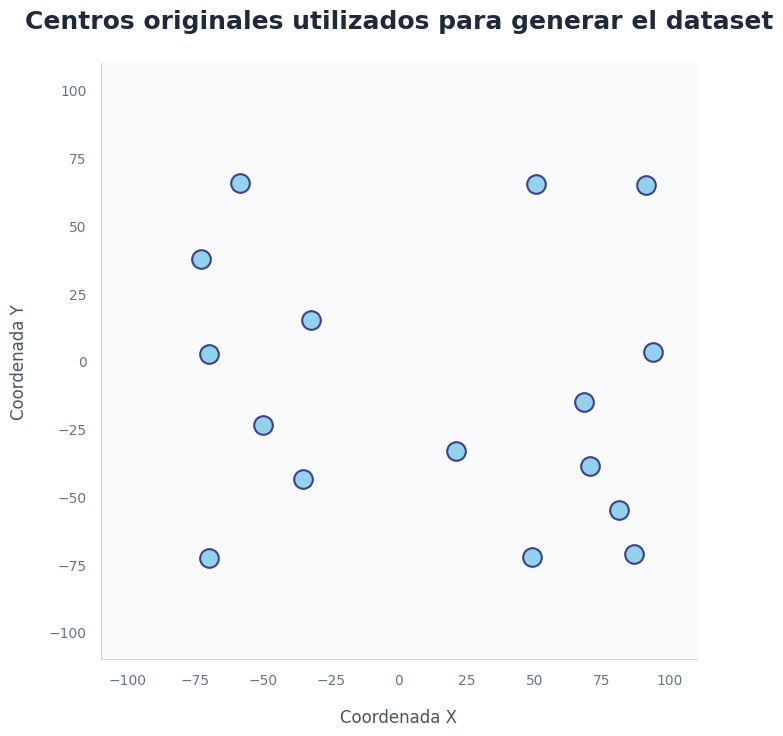

In [2]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12, 8))
fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#F8FAFC")
ax.scatter(
    blob_centers[:, 0], blob_centers[:, 1],
    color="skyblue", edgecolors="#312E81",
    linewidths=1.5, marker="o", s=180, alpha=0.9, zorder=3
)
ax.set_title(
    "Centros originales utilizados para generar el dataset",
    fontsize=18, fontweight="bold", color="#1E293B", pad=25
)
ax.set_xlabel("Coordenada X", fontsize=12, color="#475569", labelpad=15)
ax.set_ylabel("Coordenada Y", fontsize=12, color="#475569", labelpad=15)
ax.set_xlim(-110, 110)
ax.set_ylim(-110, 110)
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_color("#CBD5E1")
ax.spines["left"].set_color("#CBD5E1")
ax.tick_params(axis="both", colors="#64748B", labelsize=10, length=0, pad=10)
ax.set_aspect("equal", adjustable="box")
plt.tight_layout(pad=3)
plt.show()

## 2. Generación de los puntos

In [3]:
from sklearn.datasets import make_blobs
blob_std = semilla.uniform(8.0, 18.0, size=n_centros)
n_puntos_por_centroide = semilla.integers(100, 1001, size=n_centros)
X, y = make_blobs(
    n_samples=n_puntos_por_centroide,
    centers=blob_centers,
    cluster_std=blob_std,
    random_state=10
)
print("Cantidad de centroides:", n_centros)
print("Desviaciones estándar:", blob_std)
print("Puntos por centroide:", n_puntos_por_centroide)
print("\nTotal de puntos:", sum(n_puntos_por_centroide))
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Cantidad de centroides: 16
Desviaciones estándar: [14.49079057 16.3756376  15.76031947 11.39515575  9.48568738 12.57019387
 12.37864358 13.7421759  11.73269224 14.33825057  9.14644359 10.33090474
 15.67241017 17.87124272 16.08001079 16.42965644]
Puntos por centroide: [961 604 816 319 511 815 765 479 621 431 506 132 344 769 879 825]

Total de puntos: 9777
Dimensiones de X: (9777, 2)
Dimensiones de y: (9777,)


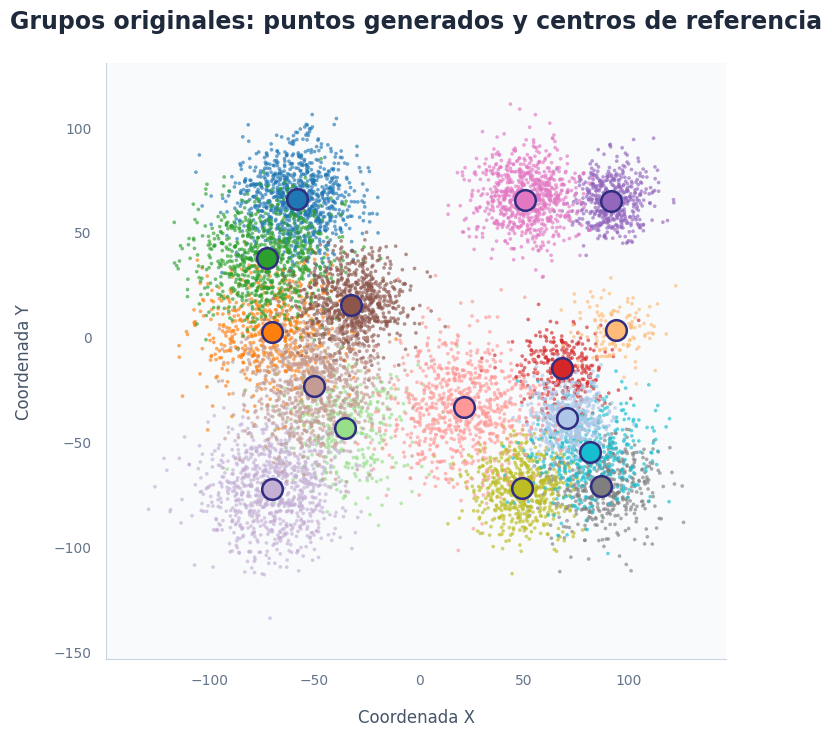

In [4]:
import matplotlib.pyplot as plt
import numpy as np
paleta_tab20 = np.array(plt.colormaps["tab20"].colors)
orden_colores = list(range(0, 20, 2)) + list(range(1, 20, 2))
colores = paleta_tab20[orden_colores]
fig, ax = plt.subplots(figsize=(12, 8))
fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#F8FAFC")
for i in range(n_centros):
    puntos = X[y == i]
    color = colores[i]
    ax.scatter(
        puntos[:, 0], puntos[:, 1],
        color=color, s=7, alpha=0.65, edgecolors="none", zorder=2
    )
    ax.scatter(
        blob_centers[i, 0], blob_centers[i, 1],
        color=color, edgecolors="#312E81", linewidths=1.8,
        marker="o", s=220, zorder=3
    )
ax.set_title(
    "Grupos originales: puntos generados y centros de referencia",
    fontsize=17, fontweight="bold", color="#1E293B", pad=25
)
ax.set_xlabel("Coordenada X", fontsize=12, color="#475569", labelpad=15)
ax.set_ylabel("Coordenada Y", fontsize=12, color="#475569", labelpad=15)
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_color("#CBD5E1")
ax.spines["left"].set_color("#CBD5E1")
ax.tick_params(axis="both", colors="#64748B", labelsize=10, length=0, pad=10)
ax.set_aspect("equal", adjustable="box")
ax.margins(0.08)
plt.tight_layout(pad=3)
plt.show()

## 3. Entrenamiento: Lloyd frente a Elkan

In [5]:
import time
from sklearn.cluster import KMeans
t0 = time.perf_counter()
kmeans_lloyd = KMeans(
    n_clusters=n_centros,
    init="k-means++",
    n_init=10,
    max_iter=300,
    algorithm="lloyd",
    random_state=10
)
kmeans_lloyd.fit(X)
t_lloyd = time.perf_counter() - t0
t0 = time.perf_counter()
kmeans_elkan = KMeans(
    n_clusters=n_centros,
    init="k-means++",
    n_init=10,
    max_iter=300,
    algorithm="elkan",
    random_state=10
)
kmeans_elkan.fit(X)
t_elkan = time.perf_counter() - t0
print("Lloyd")
print("Inercia:", kmeans_lloyd.inertia_)
print("Iteraciones:", kmeans_lloyd.n_iter_)
print("Tiempo:", t_lloyd)
print("\nElkan")
print("Inercia:", kmeans_elkan.inertia_)
print("Iteraciones:", kmeans_elkan.n_iter_)
print("Tiempo:", t_elkan)

Lloyd
Inercia: 2692938.440694805
Iteraciones: 32
Tiempo: 0.07868037200023537

Elkan
Inercia: 2692938.4406948043
Iteraciones: 32
Tiempo: 0.1351713369999743


### Comparación visual entre ambos modelos

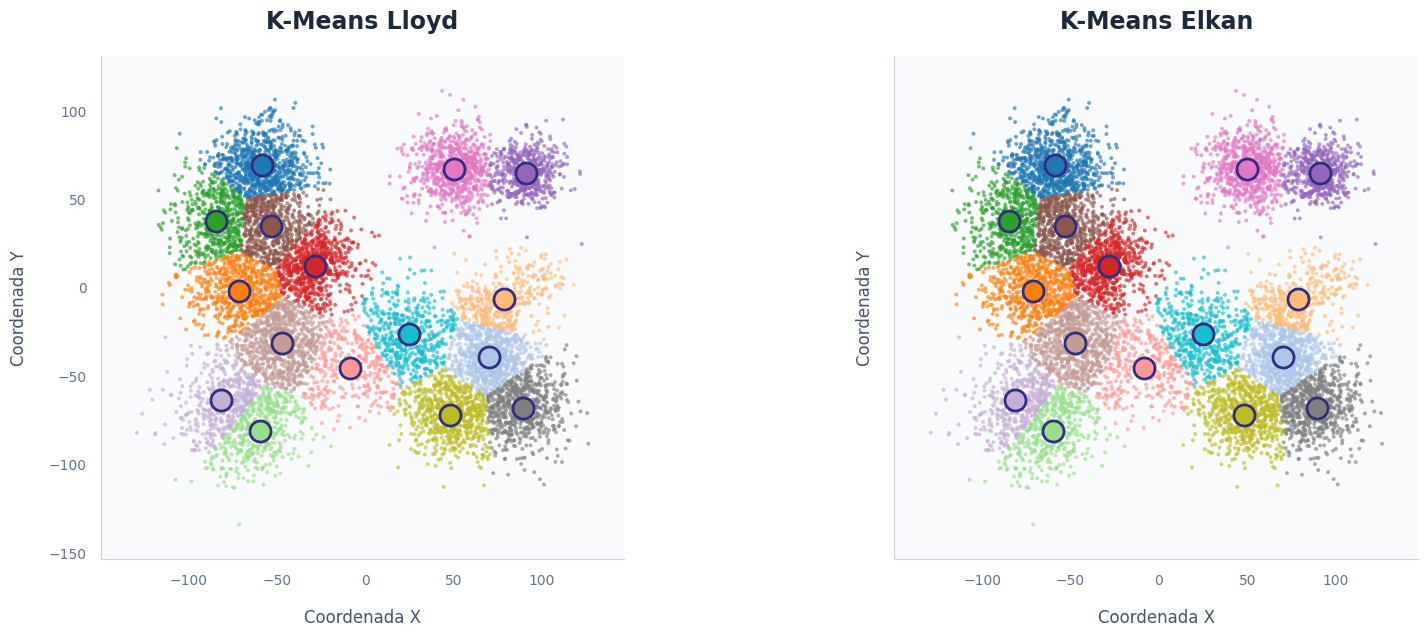

Coincidencia Lloyd vs. Elkan: 100.00%
Diferencia de inercia: 0.00000000


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
distancias_entre_modelos = cdist(
    kmeans_lloyd.cluster_centers_, kmeans_elkan.cluster_centers_
)
filas, columnas = linear_sum_assignment(distancias_entre_modelos)
equivalencias = np.empty(kmeans_elkan.n_clusters, dtype=int)
equivalencias[columnas] = filas
distancias_al_origen = cdist(blob_centers, kmeans_lloyd.cluster_centers_)
indices_originales, indices_lloyd = linear_sum_assignment(distancias_al_origen)
color_por_cluster_lloyd = np.empty(kmeans_lloyd.n_clusters, dtype=int)
color_por_cluster_lloyd[indices_lloyd] = indices_originales
fig, axes = plt.subplots(1, 2, figsize=(17, 7), sharex=True, sharey=True)
modelos = [
    (kmeans_lloyd, "K-Means Lloyd"),
    (kmeans_elkan, "K-Means Elkan"),
]
for ax, (modelo, nombre) in zip(axes, modelos):
    ax.set_facecolor("#F8FAFC")
    for i in range(modelo.n_clusters):
        puntos = X[modelo.labels_ == i]
        indice_lloyd = i if modelo is kmeans_lloyd else equivalencias[i]
        color = colores[color_por_cluster_lloyd[indice_lloyd]]
        ax.scatter(
            puntos[:, 0], puntos[:, 1], color=color,
            s=8, alpha=0.65, edgecolors="none", zorder=2
        )
        cx, cy = modelo.cluster_centers_[i]
        ax.scatter(
            cx, cy, color=color, edgecolors="#312E81",
            linewidths=2, marker="o", s=230, zorder=3
        )
    ax.set_title(nombre, fontsize=17, fontweight="bold", color="#1E293B", pad=20)
    ax.set_xlabel("Coordenada X", fontsize=12, color="#475569", labelpad=15)
    ax.set_ylabel("Coordenada Y", fontsize=12, color="#475569", labelpad=15)
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_color("#CBD5E1")
    ax.spines["left"].set_color("#CBD5E1")
    ax.tick_params(axis="both", colors="#64748B", labelsize=10, length=0, pad=10)
    ax.set_aspect("equal", adjustable="box")
    ax.margins(0.08)
fig.patch.set_facecolor("#FFFFFF")
plt.tight_layout(pad=3)
plt.show()
etiquetas_elkan_alineadas = equivalencias[kmeans_elkan.labels_]
coincidencia = np.mean(kmeans_lloyd.labels_ == etiquetas_elkan_alineadas)
print(f"Coincidencia Lloyd vs. Elkan: {coincidencia:.2%}")
print(f"Diferencia de inercia: {abs(kmeans_lloyd.inertia_ - kmeans_elkan.inertia_):.8f}")

## 4. Lloyd elegido: centros finales y vecinos más próximos

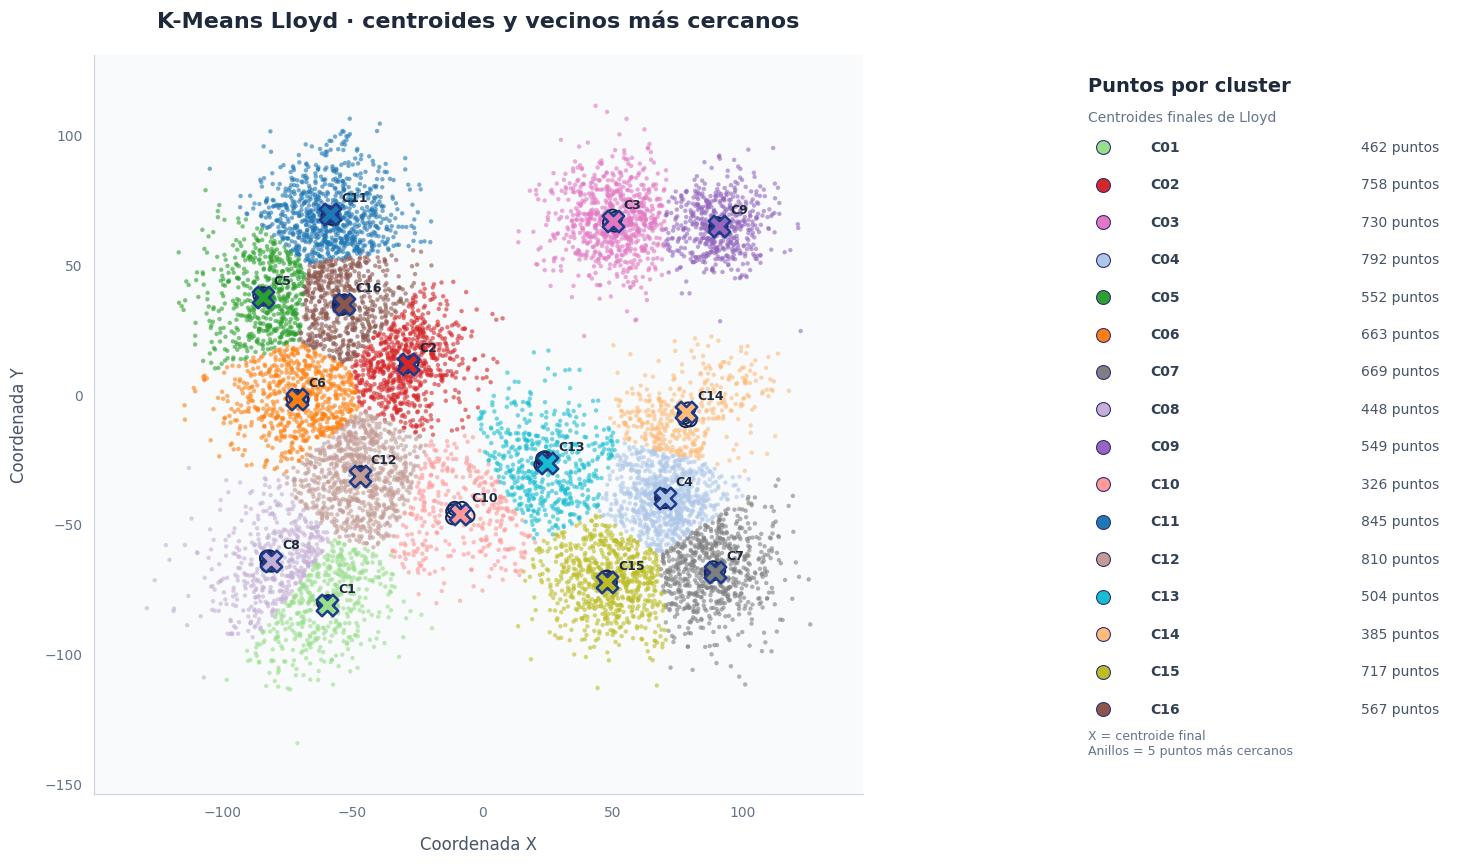

Puntos asignados en total: 9,777 / 9,777


In [7]:
import numpy as np
import matplotlib.pyplot as plt
labels = kmeans_lloyd.labels_
centroides = kmeans_lloyd.cluster_centers_
k = kmeans_lloyd.n_clusters
fig, (ax, panel) = plt.subplots(
    1, 2, figsize=(17, 9), gridspec_kw={"width_ratios": [3.4, 1.0]}
)
fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#F8FAFC")
panel.axis("off")
resumen_clusters = []
for i in range(k):
    puntos_cluster = X[labels == i]
    centroide = centroides[i]
    color = colores[color_por_cluster_lloyd[i]]
    n_puntos = len(puntos_cluster)
    ax.scatter(
        puntos_cluster[:, 0], puntos_cluster[:, 1], color=color,
        s=10, alpha=0.6, edgecolors="none", zorder=1
    )
    distancias = np.linalg.norm(puntos_cluster - centroide, axis=1)
    n_cercanos = min(5, n_puntos)
    indices_cercanos = np.argsort(distancias)[:n_cercanos]
    puntos_cercanos = puntos_cluster[indices_cercanos]
    distancias_cercanas = distancias[indices_cercanos]
    for punto in puntos_cercanos:
        ax.plot(
            [centroide[0], punto[0]], [centroide[1], punto[1]],
            color="#475569", linewidth=0.9, alpha=0.7, zorder=3
        )
    ax.scatter(
        puntos_cercanos[:, 0], puntos_cercanos[:, 1],
        facecolors="none", edgecolors="#172554", marker="o",
        linewidths=1.4, s=95, zorder=5
    )
    ax.scatter(
        centroide[0], centroide[1], color=color,
        marker="X", s=240, edgecolors="#1E3A8A",
        linewidths=1.8, zorder=6
    )
    ax.annotate(
        f"C{i+1}", tuple(centroide), xytext=(8, 9),
        textcoords="offset points", fontsize=9, fontweight="bold",
        color="#1E293B", zorder=7
    )
    resumen_clusters.append({
        "cluster": i + 1,
        "centroide": centroide,
        "n_puntos": n_puntos,
        "puntos_cercanos": puntos_cercanos,
        "distancias_cercanas": distancias_cercanas
    })
panel.set_xlim(0, 1)
panel.set_ylim(0, 1)
panel.text(0.05, 0.97, "Puntos por cluster", fontsize=14,
           fontweight="bold", color="#1E293B", va="top")
panel.text(0.05, 0.925, "Centroides finales de Lloyd", fontsize=10,
           color="#64748B", va="top")
for i, info in enumerate(resumen_clusters):
    fila_y = 0.875 - (0.76 * i / max(k - 1, 1))
    color = colores[color_por_cluster_lloyd[i]]
    panel.scatter([0.09], [fila_y], s=100, color=[color],
                  edgecolors="#312E81", linewidths=0.8)
    panel.text(0.21, fila_y, f"C{i+1:02d}", fontsize=10,
               fontweight="bold", color="#334155", va="center")
    panel.text(0.95, fila_y, f"{info['n_puntos']:,} puntos", fontsize=10,
               color="#475569", ha="right", va="center")
panel.text(0.05, 0.05, "X = centroide final\nAnillos = 5 puntos más cercanos",
           fontsize=9, color="#64748B", va="bottom")
ax.set_title("K-Means Lloyd · centroides y vecinos más cercanos",
             fontsize=16, fontweight="bold", color="#1E293B", pad=20)
ax.set_xlabel("Coordenada X", fontsize=12, color="#475569", labelpad=12)
ax.set_ylabel("Coordenada Y", fontsize=12, color="#475569", labelpad=12)
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_color("#CBD5E1")
ax.spines["left"].set_color("#CBD5E1")
ax.tick_params(axis="both", colors="#64748B", labelsize=10, length=0, pad=8)
ax.set_aspect("equal", adjustable="box")
ax.margins(0.08)
plt.tight_layout(pad=2)
plt.show()
print(f"Puntos asignados en total: {sum(c['n_puntos'] for c in resumen_clusters):,} / {len(X):,}")

### Acercamiento: los 5 puntos más próximos de cada centroide

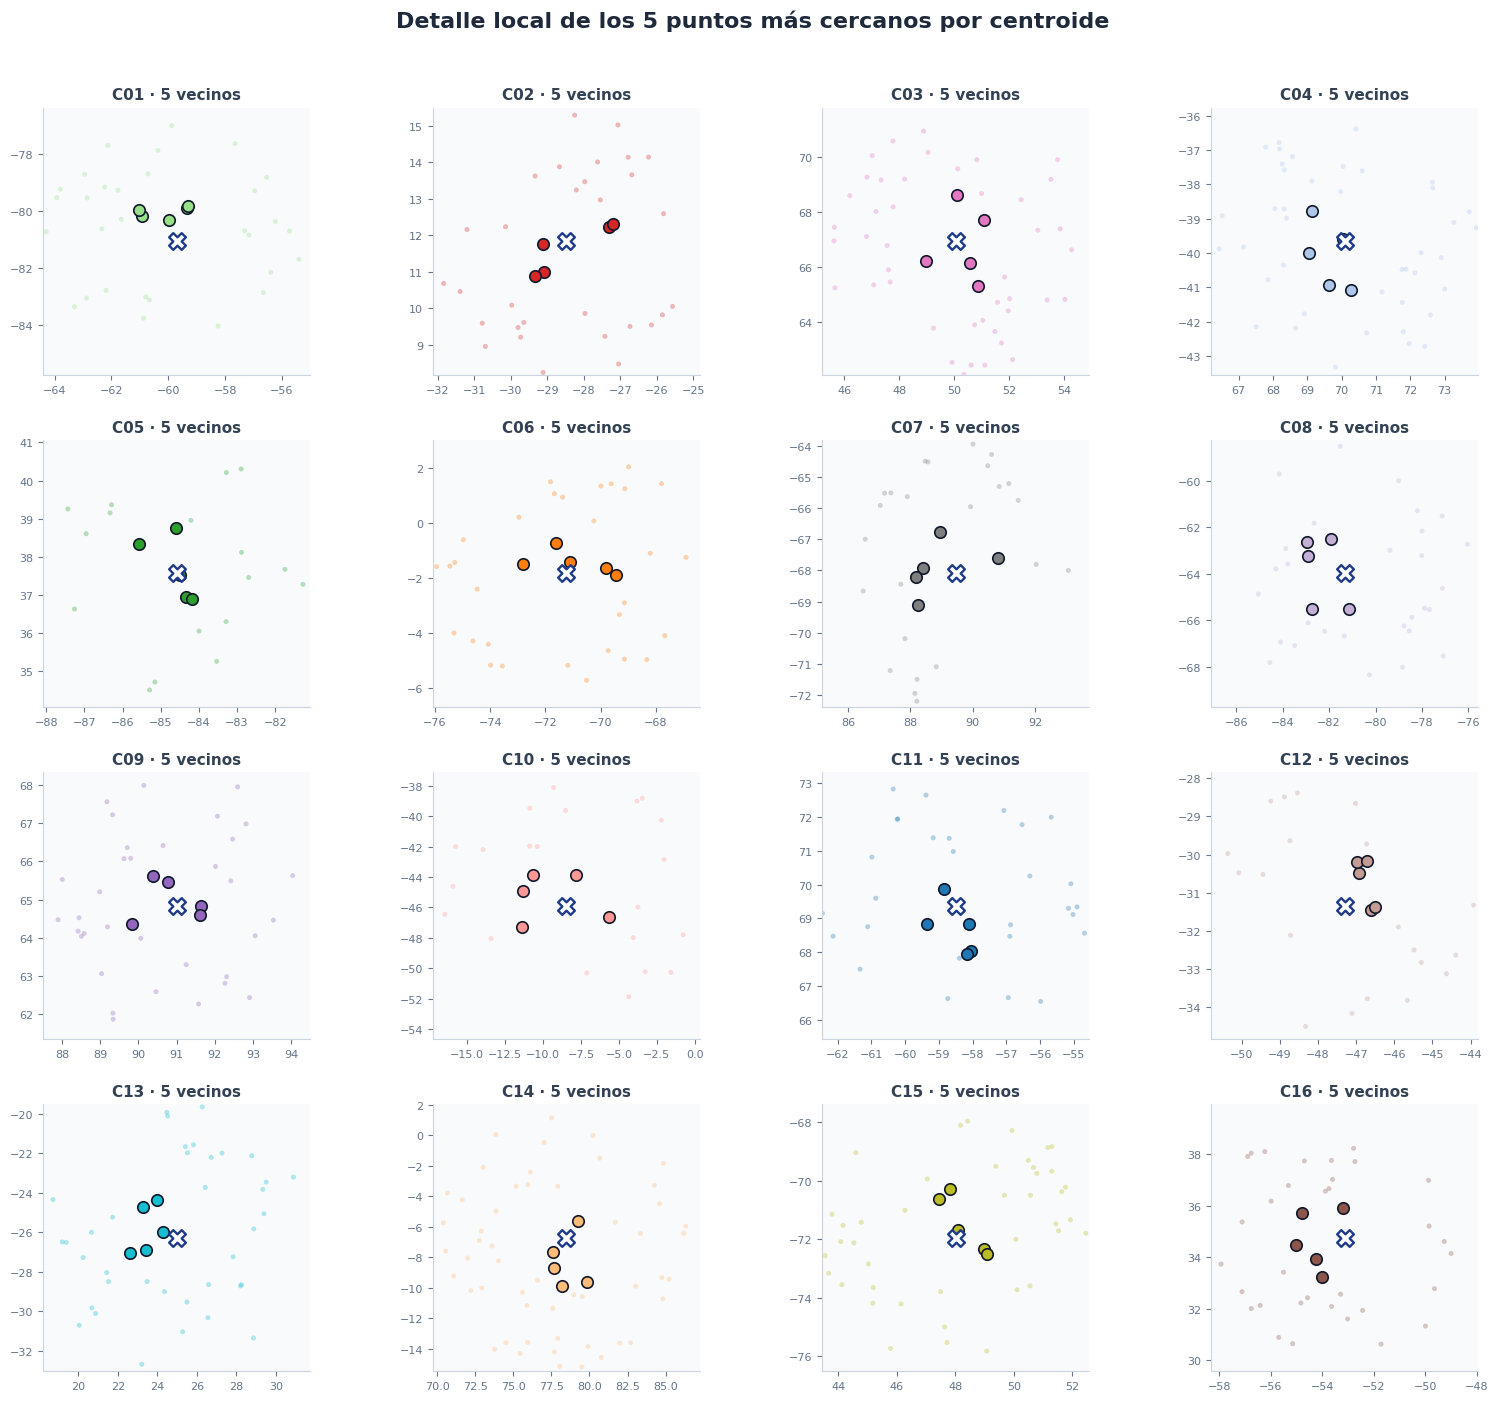

In [8]:
import math
n_columnas = min(4, k)
n_filas = math.ceil(k / n_columnas)
fig, ejes = plt.subplots(n_filas, n_columnas,
                         figsize=(4.0 * n_columnas, 3.5 * n_filas), squeeze=False)
fig.patch.set_facecolor("#FFFFFF")
for i, info in enumerate(resumen_clusters):
    ax = ejes.flat[i]
    centroide = info["centroide"]
    vecinos = info["puntos_cercanos"]
    vecinos_dist = info["distancias_cercanas"]
    puntos = X[labels == i]
    color = colores[color_por_cluster_lloyd[i]]
    radio = max(3.5, float(np.max(vecinos_dist)) * 2.7)
    cercanos_al_centro = np.linalg.norm(puntos - centroide, axis=1) <= radio
    entorno = puntos[cercanos_al_centro]
    ax.scatter(entorno[:, 0], entorno[:, 1], s=13,
               color=color, alpha=0.32, edgecolors="none")
    ax.scatter(vecinos[:, 0], vecinos[:, 1], s=68,
               color=color, alpha=1, edgecolors="#0F172A",
               linewidths=1.2, zorder=4)
    ax.scatter(centroide[0], centroide[1], marker="X", s=145,
               facecolors="white", edgecolors="#1E3A8A",
               linewidths=1.7, zorder=5)
    ax.set_xlim(centroide[0] - radio, centroide[0] + radio)
    ax.set_ylim(centroide[1] - radio, centroide[1] + radio)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(f"C{i+1:02d} · 5 vecinos", fontweight="bold", fontsize=11, color="#334155")
    ax.set_facecolor("#F8FAFC")
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_color("#CBD5E1")
    ax.spines["left"].set_color("#CBD5E1")
    ax.tick_params(labelsize=8, colors="#64748B")
for ax in ejes.flat[k:]:
    ax.axis("off")
fig.suptitle("Detalle local de los 5 puntos más cercanos por centroide",
             fontsize=16, fontweight="bold", color="#1E293B", y=1.005)
plt.tight_layout(pad=1.8)
plt.show()

In [9]:
for info in resumen_clusters:
    print(f"\n========== Cluster {info['cluster']} ==========")
    print(f"Centroide final: {info['centroide']}")
    print(f"Cantidad de puntos asignados: {info['n_puntos']}")
    print("5 puntos más cercanos al centroide:")
    for j, (punto, distancia) in enumerate(
        zip(info["puntos_cercanos"], info["distancias_cercanas"]), start=1
    ):
        print(f"  {j}. Punto: {punto}  |  Distancia: {distancia:.4f}")


========== Cluster 1 ==========
Centroide final: [-59.69882342 -81.07075266]
Cantidad de puntos asignados: 462
5 puntos más cercanos al centroide:
  1. Punto: [-59.96655515 -80.32345114]  |  Distancia: 0.7938
  2. Punto: [-59.34838516 -79.89322671]  |  Distancia: 1.2286
  3. Punto: [-59.30761813 -79.82712322]  |  Distancia: 1.3037
  4. Punto: [-60.919901   -80.18286049]  |  Distancia: 1.5098
  5. Punto: [-61.03095641 -79.9516807 ]  |  Distancia: 1.7398

========== Cluster 2 ==========
Centroide final: [-28.47838255  11.83673119]
Cantidad de puntos asignados: 758
5 puntos más cercanos al centroide:
  1. Punto: [-29.10233213  11.76009032]  |  Distancia: 0.6286
  2. Punto: [-29.09425408  10.99319849]  |  Distancia: 1.0444
  3. Punto: [-27.29544917  12.22482011]  |  Distancia: 1.2450
  4. Punto: [-29.33268968  10.88948534]  |  Distancia: 1.2756
  5. Punto: [-27.21049003  12.31040148]  |  Distancia: 1.3535

========== Cluster 3 ==========
Centroide final: [50.0498836  66.93126212]
Cantidad

## 5. Práctica 3D: K-Means Lloyd (punto 2)

### 5.1 Generación aleatoria de centroides 3D

In [10]:
import numpy as np
semilla_3d = np.random.default_rng(21)
n_centros_3d = int(semilla_3d.integers(1, 21))
distancia_minima_3d = 15
blob_centers_3d = []
while len(blob_centers_3d) < n_centros_3d:
    nuevo = semilla_3d.uniform(-100, 100, size=3)
    if all(np.linalg.norm(nuevo - centro) >= distancia_minima_3d
           for centro in blob_centers_3d):
        blob_centers_3d.append(nuevo)
blob_centers_3d = np.array(blob_centers_3d)
print("Cantidad de centroides 3D:", n_centros_3d)
print("Centroides originales (X, Y, Z):\n", np.round(blob_centers_3d, 2))

Cantidad de centroides 3D: 7
Centroides originales (X, Y, Z):
 [[ 21.17  41.96 -82.18]
 [ 26.14  96.16 -15.32]
 [-77.52  91.65  35.2 ]
 [-60.56  34.41  98.55]
 [-58.1   70.77  39.78]
 [-55.66 -63.05  90.83]
 [-31.91 -11.72  31.22]]


### 5.2 Generación de puntos con `make_blobs`

In [11]:
from sklearn.datasets import make_blobs
blob_std_3d = semilla_3d.uniform(22.0, 38.0, size=n_centros_3d)
puntos_por_centro_3d = semilla_3d.integers(100, 1001, size=n_centros_3d)
X_3d, y_3d = make_blobs(
    n_samples=puntos_por_centro_3d,
    centers=blob_centers_3d,
    cluster_std=blob_std_3d,
    random_state=21
)
print("Desviaciones estándar:", np.round(blob_std_3d, 2))
print("Puntos por centroide:", puntos_por_centro_3d)
print("Total de puntos:", len(X_3d))
print("Dimensiones de X_3d:", X_3d.shape)

Desviaciones estándar: [29.04 22.   26.16 29.56 34.18 31.7  28.88]
Puntos por centroide: [803 148 272 204 806 198 268]
Total de puntos: 2699
Dimensiones de X_3d: (2699, 3)


### 5.3 Entrenamiento con Lloyd

In [12]:
from sklearn.cluster import KMeans
kmeans_3d = KMeans(
    n_clusters=n_centros_3d,
    init="k-means++",
    n_init=10,
    max_iter=300,
    algorithm="lloyd",
    random_state=21
)
kmeans_3d.fit(X_3d)
print("Centroides aprendidos:", kmeans_3d.cluster_centers_.shape)
print("Iteraciones:", kmeans_3d.n_iter_)
print(f"Inercia: {kmeans_3d.inertia_:,.2f}")

Centroides aprendidos: (7, 3)
Iteraciones: 12
Inercia: 5,673,114.83


### 5.4 Gráficas: datos originales frente al resultado de Lloyd

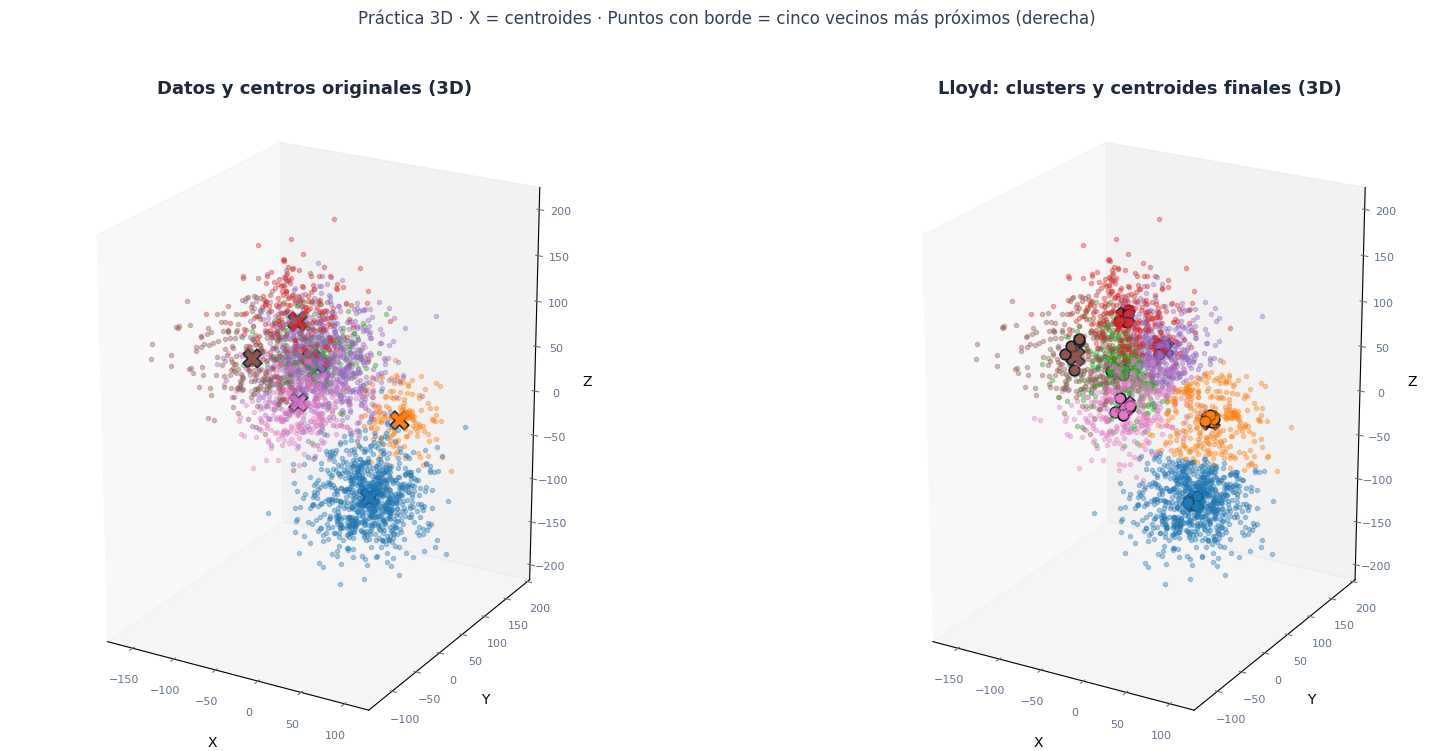

In [13]:
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
paleta = np.array(plt.colormaps["tab20"].colors)
orden = list(range(0, 20, 2)) + list(range(1, 20, 2))
colores_3d = paleta[orden]
filas, columnas = linear_sum_assignment(
    cdist(blob_centers_3d, kmeans_3d.cluster_centers_)
)
original_por_cluster = np.empty(n_centros_3d, dtype=int)
original_por_cluster[columnas] = filas
fig = plt.figure(figsize=(17, 7.5), facecolor="white")
ax_original = fig.add_subplot(121, projection="3d")
ax_lloyd = fig.add_subplot(122, projection="3d")
for i in range(n_centros_3d):
    puntos = X_3d[y_3d == i]
    ax_original.scatter(*puntos.T, color=colores_3d[i], s=9,
                        alpha=0.35, depthshade=False)
    ax_original.scatter(*blob_centers_3d[i], color=colores_3d[i],
                        marker="X", s=180, edgecolors="#1E293B",
                        linewidths=1.3, depthshade=False)
    asignados = X_3d[kmeans_3d.labels_ == i]
    centro = kmeans_3d.cluster_centers_[i]
    color = colores_3d[original_por_cluster[i]]
    ax_lloyd.scatter(*asignados.T, color=color, s=9,
                     alpha=0.35, depthshade=False)
    ax_lloyd.scatter(*centro, color=color, marker="X", s=180,
                     edgecolors="#1E293B", linewidths=1.3,
                     depthshade=False)
    distancias = np.linalg.norm(asignados - centro, axis=1)
    cercanos = asignados[np.argsort(distancias)[:5]]
    ax_lloyd.scatter(*cercanos.T, color=color, s=58,
                     alpha=1, edgecolors="#111827", linewidths=1.2,
                     depthshade=False)
minimos = X_3d.min(axis=0)
maximos = X_3d.max(axis=0)
margen = (maximos - minimos) * 0.06
extension = maximos - minimos + 2 * margen
for ax, titulo in [(ax_original, "Datos y centros originales (3D)"),
                   (ax_lloyd, "Lloyd: clusters y centroides finales (3D)")]:
    ax.set_title(titulo, fontsize=13, fontweight="bold",
                 color="#1E293B", pad=18)
    ax.set(xlim=(minimos[0]-margen[0], maximos[0]+margen[0]),
           ylim=(minimos[1]-margen[1], maximos[1]+margen[1]),
           zlim=(minimos[2]-margen[2], maximos[2]+margen[2]))
    ax.set_xlabel("X", labelpad=8)
    ax.set_ylabel("Y", labelpad=8)
    ax.set_zlabel("Z", labelpad=8)
    ax.set_box_aspect(extension)
    ax.view_init(elev=22, azim=-60)
    ax.grid(False)
    ax.tick_params(labelsize=8, colors="#64748B")
fig.suptitle("Práctica 3D · X = centroides · Puntos con borde = cinco vecinos más próximos (derecha)",
             fontsize=12, color="#334155", y=0.995)
plt.tight_layout(pad=2)
plt.show()

### 5.5 Resumen de los centroides finales

In [14]:
for i, centro in enumerate(kmeans_3d.cluster_centers_):
    puntos = X_3d[kmeans_3d.labels_ == i]
    distancias = np.linalg.norm(puntos - centro, axis=1)
    cinco_distancias = np.sort(distancias)[:5]
    xyz = ", ".join(f"{valor:.2f}" for valor in centro)
    vecinos = ", ".join(f"{d:.2f}" for d in cinco_distancias)
    print(f"C{i+1:02d} | ({xyz}) | {len(puntos)} puntos | Vecinos: {vecinos}")

C01 | (-89.35, 75.68, 25.62) | 437 puntos | Vecinos: 5.34, 6.40, 7.91, 7.94, 7.95
C02 | (21.49, 39.94, -87.69) | 730 puntos | Vecinos: 2.60, 3.65, 6.57, 9.03, 9.36
C03 | (-58.33, -63.15, 92.36) | 202 puntos | Vecinos: 10.84, 14.67, 16.04, 17.71, 17.85
C04 | (-60.20, 39.09, 102.46) | 315 puntos | Vecinos: 6.20, 6.75, 7.65, 7.70, 9.29
C05 | (-32.87, -6.56, 25.44) | 336 puntos | Vecinos: 6.82, 8.90, 10.79, 13.06, 14.40
C06 | (15.65, 84.43, -12.44) | 297 puntos | Vecinos: 3.74, 3.87, 5.73, 9.38, 9.42
C07 | (-48.57, 100.43, 49.80) | 382 puntos | Vecinos: 6.20, 7.13, 7.59, 7.78, 9.98


# 6. Punto 3 — Imágenes reales: Quick, Draw!

## 6.1. Conectar Google Drive y cargar las imágenes

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount("/content/drive")
carpeta_datos = "/content/drive/MyDrive/Colab Notebooks/machine learning/datasets/"
archivos_clases = ["apple.npy", "car.npy", "clock.npy", "cat.npy"]
nombres_clases = ["Manzana", "Automóvil", "Reloj", "Gato"]
ejemplos_por_clase = 15000
for archivo in archivos_clases:
    ruta_archivo = os.path.join(carpeta_datos, archivo)
    if not os.path.isfile(ruta_archivo):
        raise FileNotFoundError(f"No se encontró: {ruta_archivo}")
print("Archivos encontrados en Google Drive:")
for nombre in archivos_clases:
    print(" -", nombre)

## 6.2. Preparar los datos y sus etiquetas de referencia

In [ ]:
imagenes_por_categoria = []
etiquetas_por_categoria = []
for numero_clase, archivo in enumerate(archivos_clases):
    ruta_archivo = os.path.join(carpeta_datos, archivo)
    dibujos = np.load(ruta_archivo, mmap_mode="r")
    if dibujos.ndim != 2 or dibujos.shape[1] != 784:
        raise ValueError(f"{archivo}: se esperaban imágenes con 784 píxeles; forma recibida {dibujos.shape}")
    if len(dibujos) < ejemplos_por_clase:
        raise ValueError(f"{archivo}: contiene {len(dibujos)} imágenes; se requieren {ejemplos_por_clase}")
    imagenes_por_categoria.append(np.asarray(dibujos[:ejemplos_por_clase]))
    etiquetas_por_categoria.append(np.full(ejemplos_por_clase, numero_clase, dtype=int))
imagenes = np.vstack(imagenes_por_categoria).astype(np.float32) / 255.0
etiquetas_originales = np.concatenate(etiquetas_por_categoria)
del imagenes_por_categoria, etiquetas_por_categoria
print("Total de imágenes:", len(imagenes))
print("Dimensiones (imágenes, características):", imagenes.shape)
print("Categorías:", dict(enumerate(nombres_clases)))

## 6.3. Separar entrenamiento y prueba

In [ ]:
from sklearn.model_selection import train_test_split
imagenes_entrenamiento, imagenes_prueba, etiquetas_entrenamiento, etiquetas_prueba = train_test_split(
    imagenes,
    etiquetas_originales,
    test_size=0.20,
    random_state=42,
    stratify=etiquetas_originales
)
del imagenes, etiquetas_originales
print("Entrenamiento:", imagenes_entrenamiento.shape)
print("Prueba:", imagenes_prueba.shape)

In [ ]:
fig, ejes = plt.subplots(4, 5, figsize=(11, 8))
for numero_clase in range(4):
    posiciones = np.flatnonzero(etiquetas_entrenamiento == numero_clase)[:5]
    for columna, posicion in enumerate(posiciones):
        eje = ejes[numero_clase, columna]
        eje.imshow(imagenes_entrenamiento[posicion].reshape(28, 28), cmap="gray")
        eje.set_title(nombres_clases[numero_clase], fontsize=9)
        eje.axis("off")
fig.suptitle("Google Quick, Draw! — muestras del dataset", fontsize=15, weight="bold")
plt.tight_layout()
plt.show()

# 7. K-Means sobre las imágenes sin etiquetas

In [ ]:
from sklearn.cluster import KMeans
numero_grupos = 50
modelo_kmeans_imagenes = KMeans(
    n_clusters=numero_grupos,
    init="k-means++",
    n_init=3,
    max_iter=200,
    algorithm="lloyd",
    random_state=42
)
distancias_a_centroides = modelo_kmeans_imagenes.fit_transform(imagenes_entrenamiento)
print("Grupos formados:", numero_grupos)
print("Matriz de distancias:", distancias_a_centroides.shape)
print("Iteraciones de Lloyd:", modelo_kmeans_imagenes.n_iter_)

## 7.1. Seleccionar una imagen representativa por grupo

In [ ]:
posiciones_representantes = np.argmin(distancias_a_centroides, axis=0)
imagenes_representantes = imagenes_entrenamiento[posiciones_representantes]
print("Imágenes seleccionadas:", imagenes_representantes.shape)
print("Posiciones de las primeras representantes:", posiciones_representantes[:10])

# 8. Etiquetar los representantes y entrenar un clasificador inicial

In [ ]:
etiquetas_representantes = etiquetas_entrenamiento[posiciones_representantes]
fig, ejes = plt.subplots(5, 10, figsize=(14, 8))
for numero, eje in enumerate(ejes.flat):
    eje.imshow(imagenes_representantes[numero].reshape(28, 28), cmap="gray")
    eje.set_title(nombres_clases[etiquetas_representantes[numero]], fontsize=8)
    eje.axis("off")
fig.suptitle("50 imágenes representativas etiquetadas", fontsize=15, weight="bold")
plt.tight_layout()
plt.show()
print("Etiquetas verificadas inicialmente:", len(etiquetas_representantes))
print("Etiquetas disponibles en los representantes:", np.unique(etiquetas_representantes))

## 8.1. Regresión logística con las 50 etiquetas verificadas

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
clasificador_inicial = LogisticRegression(max_iter=300, solver="lbfgs", random_state=42)
clasificador_inicial.fit(imagenes_representantes, etiquetas_representantes)
predicciones_iniciales = clasificador_inicial.predict(imagenes_prueba)
exactitud_inicial = accuracy_score(etiquetas_prueba, predicciones_iniciales)
print(f"Exactitud con 50 etiquetas verificadas: {exactitud_inicial:.2%}")

# 9. Aprendizaje semisupervisado: propagar a TODO el entrenamiento

In [ ]:
etiquetas_propagadas = np.empty(len(imagenes_entrenamiento), dtype=int)
for numero_grupo in range(numero_grupos):
    pertenecen_al_grupo = (modelo_kmeans_imagenes.labels_ == numero_grupo)
    etiquetas_propagadas[pertenecen_al_grupo] = etiquetas_representantes[numero_grupo]
print("Etiquetas propagadas:", len(etiquetas_propagadas))
print("Primeras 15:", etiquetas_propagadas[:15])

## 9.1. Entrenar con todas las imágenes y etiquetas propagadas

In [ ]:
clasificador_semisupervisado = LogisticRegression(max_iter=300, solver="lbfgs", random_state=42)
clasificador_semisupervisado.fit(imagenes_entrenamiento, etiquetas_propagadas)
predicciones_semisupervisadas = clasificador_semisupervisado.predict(imagenes_prueba)
exactitud_semisupervisada = accuracy_score(etiquetas_prueba, predicciones_semisupervisadas)
print(f"Exactitud con etiquetas propagadas: {exactitud_semisupervisada:.2%}")

# 10. Aprendizaje activo: seleccionar imágenes con menor confianza

In [ ]:
posiciones_sin_etiqueta_verificada = np.setdiff1d(
    np.arange(len(imagenes_entrenamiento)), posiciones_representantes
)
probabilidades = clasificador_semisupervisado.predict_proba(
    imagenes_entrenamiento[posiciones_sin_etiqueta_verificada]
)
confianza_de_cada_imagen = np.max(probabilidades, axis=1)
orden_por_menor_confianza = np.argsort(confianza_de_cada_imagen)
cantidad_consultas = 100
posiciones_para_consultar = posiciones_sin_etiqueta_verificada[
    orden_por_menor_confianza[:cantidad_consultas]
]
print("Imágenes nuevas seleccionadas:", len(posiciones_para_consultar))
print("Confianza estimada mínima:", f"{confianza_de_cada_imagen.min():.2%}")

## 10.1. Consultar las etiquetas reales de las imágenes seleccionadas

In [ ]:
etiquetas_consultadas = etiquetas_entrenamiento[posiciones_para_consultar]
etiquetas_anteriores = etiquetas_propagadas[posiciones_para_consultar]
cantidad_corregidas = np.count_nonzero(etiquetas_consultadas != etiquetas_anteriores)
print("Nuevas etiquetas verificadas:", len(etiquetas_consultadas))
print("Pseudoetiquetas que necesitaban corrección:", cantidad_corregidas)
fig, ejes = plt.subplots(4, 5, figsize=(11, 8))
for numero, eje in enumerate(ejes.flat):
    posicion = posiciones_para_consultar[numero]
    eje.imshow(imagenes_entrenamiento[posicion].reshape(28, 28), cmap="gray")
    eje.set_title(nombres_clases[etiquetas_entrenamiento[posicion]], fontsize=9)
    eje.axis("off")
fig.suptitle("Muestra de imágenes consultadas en aprendizaje activo", fontsize=14, weight="bold")
plt.tight_layout()
plt.show()

## 10.2. Reentrenar con las etiquetas corregidas

In [ ]:
etiquetas_con_correcciones = etiquetas_propagadas.copy()
etiquetas_con_correcciones[posiciones_para_consultar] = etiquetas_consultadas
clasificador_activo = LogisticRegression(max_iter=300, solver="lbfgs", random_state=42)
clasificador_activo.fit(imagenes_entrenamiento, etiquetas_con_correcciones)
predicciones_activas = clasificador_activo.predict(imagenes_prueba)
exactitud_activa = accuracy_score(etiquetas_prueba, predicciones_activas)
print(f"Exactitud después del aprendizaje activo: {exactitud_activa:.2%}")

# 11. Resultados de la práctica

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
print("DATASET: GOOGLE QUICK, DRAW!")
print("Categorías:", ", ".join(nombres_clases))
print(f"Entrenamiento: {len(imagenes_entrenamiento):,} | Prueba: {len(imagenes_prueba):,}")
print(f"K-Means Lloyd: {numero_grupos} grupos")
print(f"Etiquetas reales iniciales: {len(posiciones_representantes)}")
print(f"Etiquetas reales nuevas (activo): {len(posiciones_para_consultar)}")
print(f"Etiquetas propagadas (semisupervisado): {len(etiquetas_propagadas):,}")
print("\nEXACTITUD EN EL CONJUNTO DE PRUEBA")
print(f"  Clasificador inicial (representantes): {exactitud_inicial:.2%}")
print(f"  Aprendizaje semisupervisado:         {exactitud_semisupervisada:.2%}")
print(f"  Aprendizaje activo:                 {exactitud_activa:.2%}")
fig, eje = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    etiquetas_prueba,
    predicciones_activas,
    labels=np.arange(len(nombres_clases)),
    display_labels=nombres_clases,
    cmap="Blues",
    ax=eje,
    colorbar=False
)
eje.set_title("Matriz de confusión — clasificador tras aprendizaje activo")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()